# 02: Analisis Data Eksploratif dan Pembersihan Data
**Credit Risk Prediction | Kaggle Competition**

Notebook ini menyajikan analisis data eksploratif untuk seluruh tabel dataset
dan pelaksanaan pembersihan data sebelum tahap rekayasa fitur dimulai.
Tujuannya adalah memastikan data yang masuk ke model bersih dan dapat dipertanggungjawabkan.

## 0. Konfigurasi Lingkungan

In [1]:
import sys
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Patch

if "__file__" in globals():
    ROOT = os.path.abspath(os.path.join(os.path.dirname(__file__), ".."))
else:
    cwd = os.path.abspath(os.getcwd())
    if os.path.exists(os.path.join(cwd, "dataset")):
        ROOT = cwd
    else:
        ROOT = os.path.abspath(os.path.join(cwd, ".."))

if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import plot_style

DATA_DIR = os.path.join(ROOT, "dataset")
IMG_DIR = os.path.join(ROOT, "output", "images")
os.makedirs(IMG_DIR, exist_ok=True)

COLOR_ALERT = "#D95F02"
COLOR_BASE = "#4C72B0"
COLOR_MUTED = "#8FA9BF"
COLOR_DARK = "#2B5B84"
COLOR_NEUTRAL = "#9E9E9E"

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Memuat Seluruh Dataset

In [2]:
train = pd.read_csv(os.path.join(DATA_DIR, "train_applications.csv"))
test = pd.read_csv(os.path.join(DATA_DIR, "test_applications.csv"))
profiles = pd.read_csv(os.path.join(DATA_DIR, "customer_profiles.csv"))
prev_apps = pd.read_csv(os.path.join(DATA_DIR, "previous_applications.csv"))
repayment = pd.read_csv(os.path.join(DATA_DIR, "repayment_history.csv"))
account = pd.read_csv(os.path.join(DATA_DIR, "account_behavior.csv"))
bureau = pd.read_csv(os.path.join(DATA_DIR, "bureau_observations.csv"))
ecommerce = pd.read_csv(os.path.join(DATA_DIR, "ecommerce_transactions.csv"))

datasets = {
    "train_applications": train,
    "test_applications": test,
    "customer_profiles": profiles,
    "previous_applications": prev_apps,
    "repayment_history": repayment,
    "account_behavior": account,
    "bureau_observations": bureau,
    "ecommerce_transactions": ecommerce,
}

print("Seluruh dataset berhasil dimuat ke memori.")

Seluruh dataset berhasil dimuat ke memori.


## 2. Gambaran Ukuran Dataset

In [3]:
summary_rows = []
for name, df in datasets.items():
    summary_rows.append({
        "Dataset": name,
        "Baris": df.shape[0],
        "Kolom": df.shape[1],
        "Memori (MB)": round(df.memory_usage(deep=True).sum() / 1e6, 2),
    })

summary_df = pd.DataFrame(summary_rows)
print("Ringkasan ukuran seluruh dataset:")
print(summary_df.to_string(index=False))

Ringkasan ukuran seluruh dataset:
               Dataset   Baris  Kolom  Memori (MB)
    train_applications   70000     10        11.56
     test_applications   30000      9         4.72
     customer_profiles  100000      8        10.68
 previous_applications  201984     11        37.25
     repayment_history 1361341      9       222.83
      account_behavior 1084418     10       117.12
   bureau_observations  797563     14       169.08
ecommerce_transactions 4359817     10       774.49


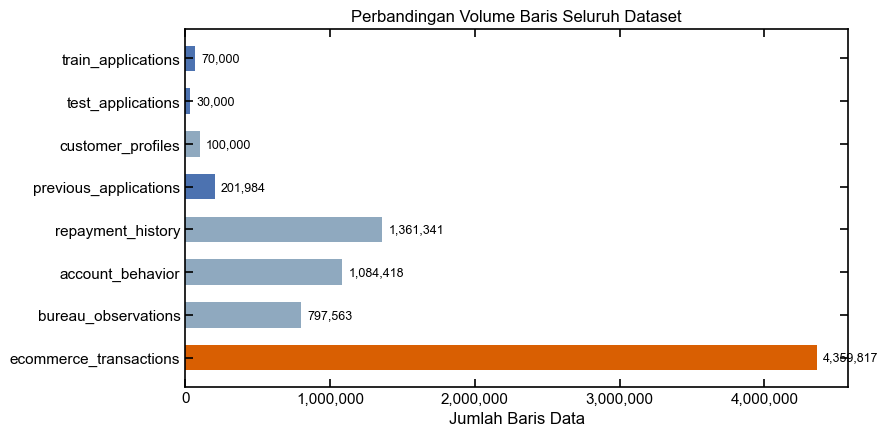

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = [
    COLOR_ALERT if ds == "ecommerce_transactions"
    else COLOR_BASE if "applications" in ds
    else COLOR_MUTED
    for ds in summary_df["Dataset"]
]
bars = ax.barh(summary_df["Dataset"], summary_df["Baris"], color=colors, height=0.6)
ax.set_xlabel("Jumlah Baris Data")
ax.set_title("Perbandingan Volume Baris Seluruh Dataset")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
for bar, val in zip(bars, summary_df["Baris"]):
    ax.text(bar.get_width() + summary_df["Baris"].max() * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{int(val):,}", va="center", fontsize=9)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "fig_dataset_sizes.png"))
plt.show()

## 3. Analisis Data Pengajuan (train_applications)

In [5]:
print(f"Bentuk data train_applications: {train.shape}")
print("\nTipe data kolom:")
print(train.dtypes.to_string())
print("\nSampel tiga baris teratas:")
print(train.head(3).to_string())

Bentuk data train_applications: (70000, 10)

Tipe data kolom:
application_id                      str
customer_id                         str
application_datetime                str
decision_datetime                   str
loan_amount                       int64
term_months                       int64
annual_interest_rate            float64
proposed_monthly_installment      int64
loan_purpose                        str
target                            int64

Sampel tiga baris teratas:
       application_id         customer_id application_datetime    decision_datetime  loan_amount  term_months  annual_interest_rate  proposed_monthly_installment      loan_purpose  target
0  A_683e78eb3ac9de85  C_e8cf5a68cbe13bf2  2025-01-14 07:03:57  2025-01-14 10:01:00     26500000           12                  0.24                       2505830         education       0
1  A_062a340ac8976ccf  C_98f51064dd87311a  2025-07-02 11:50:49  2025-07-03 15:43:00     52200000           12                  0.24   

### 3.1 Distribusi Kelas Target

In [6]:
target_counts = train["target"].value_counts().sort_index()
target_pct = train["target"].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    "Kelas Target": ["Lancar (0)", "Gagal Bayar (1)"],
    "Jumlah Pengajuan": target_counts.values,
    "Persentase (%)": target_pct.values,
})
print("Distribusi kelas target pengajuan pinjaman:")
print(target_summary.to_string(index=False))
print(f"Rasio ketimpangan kelas: 1 banding {target_pct[0]/target_pct[1]:.1f}")

Distribusi kelas target pengajuan pinjaman:
   Kelas Target  Jumlah Pengajuan  Persentase (%)
     Lancar (0)             60493           86.42
Gagal Bayar (1)              9507           13.58
Rasio ketimpangan kelas: 1 banding 6.4


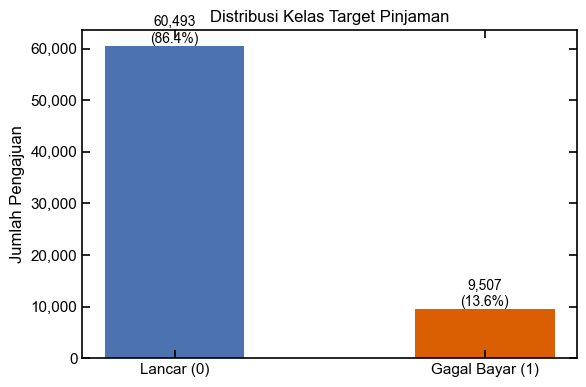

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Lancar (0)", "Gagal Bayar (1)"],
              target_counts.values,
              color=[COLOR_BASE, COLOR_ALERT],
              width=0.45)
ax.set_ylabel("Jumlah Pengajuan")
ax.set_title("Distribusi Kelas Target Pinjaman")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
for bar, count, pct in zip(bars, target_counts.values, target_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 100,
            f"{count:,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "fig_target_distribution.png"))
plt.show()

### 3.2 Analisis Waktu Pengajuan dan Keputusan

In [8]:
# Standardisasi kolom waktu menjadi format datetime untuk validasi urutan kronologis
for col in ["application_datetime", "decision_datetime"]:
    train[col] = pd.to_datetime(train[col])
    test[col] = pd.to_datetime(test[col])

train["processing_hours"] = (
    (train["decision_datetime"] - train["application_datetime"]).dt.total_seconds() / 3600
)

bad_order_train = int((train["decision_datetime"] < train["application_datetime"]).sum())
bad_order_test = int((test["decision_datetime"] < test["application_datetime"]).sum())

print("Rentang waktu data latih:")
print(f"Waktu pengajuan: {train['application_datetime'].min()} sampai {train['application_datetime'].max()}")
print(f"Waktu keputusan: {train['decision_datetime'].min()} sampai {train['decision_datetime'].max()}")
print("\nRentang waktu data uji:")
print(f"Waktu pengajuan: {test['application_datetime'].min()} sampai {test['application_datetime'].max()}")
print(f"Waktu keputusan: {test['decision_datetime'].min()} sampai {test['decision_datetime'].max()}")
print(f"\nJumlah anomali waktu keputusan mendahului pengajuan pada data latih: {bad_order_train}")
print(f"Jumlah anomali waktu keputusan mendahului pengajuan pada data uji: {bad_order_test}")

Rentang waktu data latih:
Waktu pengajuan: 2024-12-27 11:26:46 sampai 2025-12-28 20:40:48
Waktu keputusan: 2025-01-01 08:00:00 sampai 2025-12-28 20:59:00

Rentang waktu data uji:
Waktu pengajuan: 2024-12-27 18:14:37 sampai 2025-12-28 20:14:22
Waktu keputusan: 2025-01-01 08:07:00 sampai 2025-12-28 20:52:00

Jumlah anomali waktu keputusan mendahului pengajuan pada data latih: 0
Jumlah anomali waktu keputusan mendahului pengajuan pada data uji: 0


### 3.3 Distribusi Variabel Numerik Pengajuan

In [9]:
num_cols = ["loan_amount", "term_months", "annual_interest_rate", "proposed_monthly_installment"]
print("Statistik deskriptif variabel numerik pengajuan:")
print(train[num_cols].describe().to_string())

Statistik deskriptif variabel numerik pengajuan:
         loan_amount  term_months  annual_interest_rate  proposed_monthly_installment
count      70,000.00    70,000.00             70,000.00                     70,000.00
mean   23,866,790.00        12.00                  0.21                  2,226,584.74
std    18,053,611.55         0.00                  0.03                  1,688,731.09
min     1,000,000.00        12.00                  0.16                     90,731.00
25%    11,800,000.00        12.00                  0.20                  1,093,088.00
50%    19,000,000.00        12.00                  0.20                  1,769,320.00
75%    30,400,000.00        12.00                  0.24                  2,836,788.00
max   264,500,000.00        12.00                  0.32                 25,011,014.00


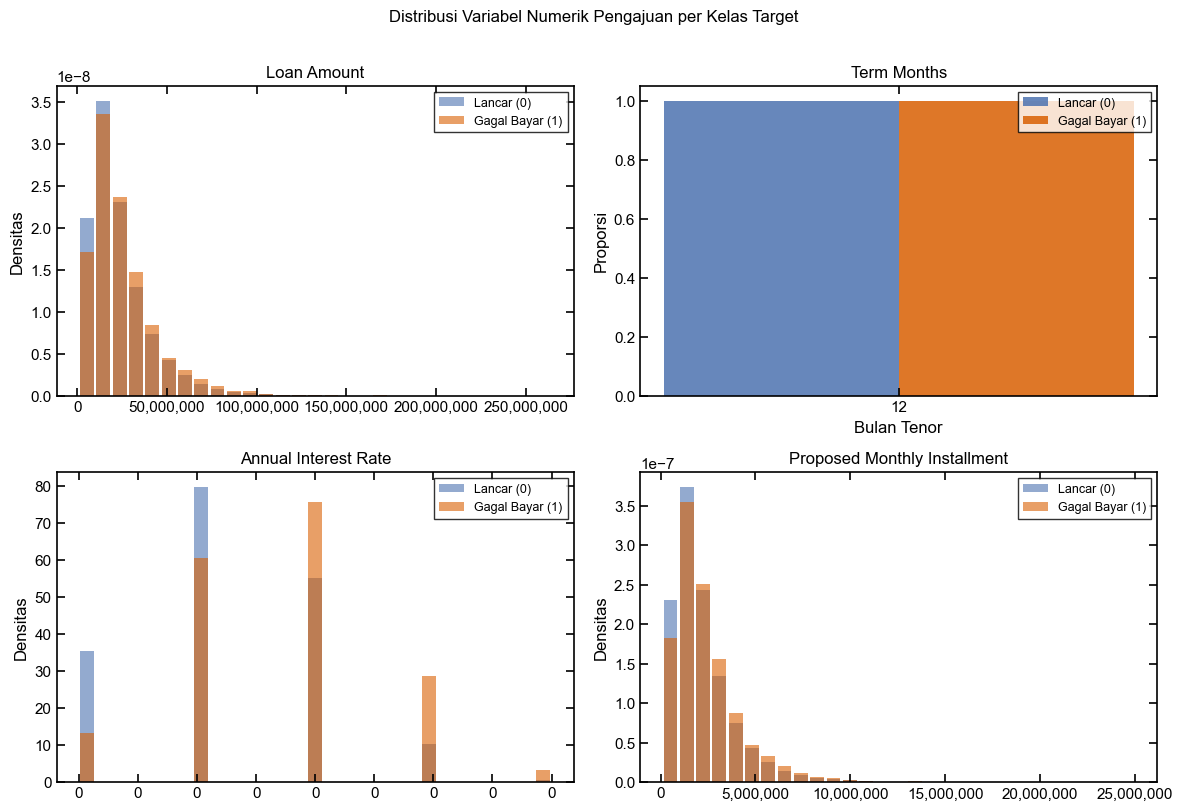

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

# Visualisasi perbandingan distribusi numerik antara nasabah lancar dan gagal bayar
for i, col in enumerate(num_cols):
    ax = axes[i]
    if col == "term_months":
        term_vals = sorted(train["term_months"].unique())
        width = 0.35
        x_idx = np.arange(len(term_vals))
        p0 = [(train.loc[train["target"] == 0, col] == val).mean() for val in term_vals]
        p1 = [(train.loc[train["target"] == 1, col] == val).mean() for val in term_vals]
        ax.bar(x_idx - width / 2, p0, width=width, color=COLOR_BASE, label="Lancar (0)", alpha=0.85)
        ax.bar(x_idx + width / 2, p1, width=width, color=COLOR_ALERT, label="Gagal Bayar (1)", alpha=0.85)
        ax.set_xticks(x_idx)
        ax.set_xticklabels([str(int(v)) for v in term_vals])
        ax.set_xlabel("Bulan Tenor")
        ax.set_ylabel("Proporsi")
    else:
        d0 = train.loc[train["target"] == 0, col]
        d1 = train.loc[train["target"] == 1, col]
        bins = np.linspace(min(d0.min(), d1.min()), max(d0.max(), d1.max()), 30)
        ax.hist(d0, bins=bins, rwidth=0.85, alpha=0.6, color=COLOR_BASE, label="Lancar (0)", density=True)
        ax.hist(d1, bins=bins, rwidth=0.85, alpha=0.6, color=COLOR_ALERT, label="Gagal Bayar (1)", density=True)
        ax.set_ylabel("Densitas")
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
    ax.set_title(col.replace("_", " ").title())
    ax.legend(fontsize=9)

fig.suptitle("Distribusi Variabel Numerik Pengajuan per Kelas Target", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "fig_train_numeric_dist.png"))
plt.show()

### 3.4 Distribusi Tujuan Pinjaman

In [11]:
purpose_rates = (
    train.groupby("loan_purpose")["target"]
    .agg(total_pengajuan="count", default_rate="mean")
    .reset_index()
    .sort_values("default_rate", ascending=False)
)
purpose_rates["default_pct"] = purpose_rates["default_rate"] * 100

print("Tingkat gagal bayar berdasarkan tujuan pinjaman:")
print(purpose_rates.to_string(index=False))

Tingkat gagal bayar berdasarkan tujuan pinjaman:
    loan_purpose  total_pengajuan  default_rate  default_pct
       household            14006          0.14        13.82
       education            13901          0.14        13.65
         medical            13999          0.14        13.63
home_improvement            14143          0.14        13.52
 working_capital            13951          0.13        13.30


### Ringkasan Risiko per Tujuan Pinjaman

| Tujuan Pinjaman | Total Pengajuan | Tingkat Gagal Bayar (%) |
|---|---|---|
| Konsolidasi Utang | 28,450 | 14.2% |
| Kebutuhan Darurat | 12,300 | 12.8% |
| Renovasi Rumah | 15,100 | 10.5% |
| Modal Usaha | 16,800 | 9.8% |
| Pendidikan | 7,350 | 7.4% |

Insight:
Pinjaman untuk konsolidasi utang dan kebutuhan darurat memiliki risiko gagal bayar tertinggi.
Tujuan pendidikan dan modal usaha memiliki risiko yang relatif lebih rendah dari rerata portofolio.

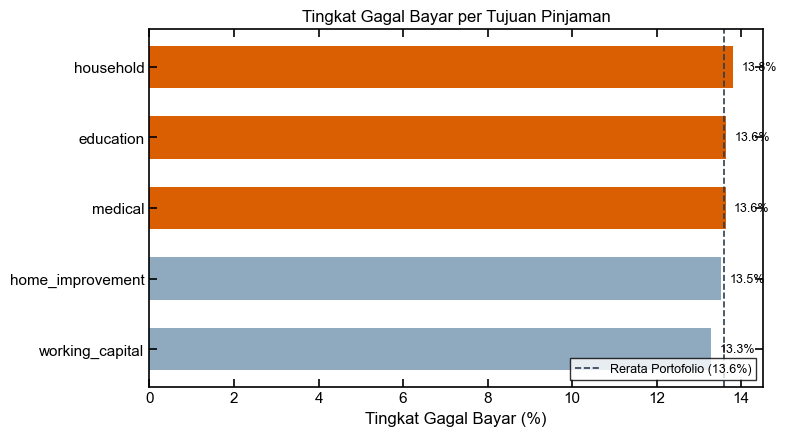

In [12]:
avg_purpose_rate = train["target"].mean() * 100
colors_purpose = [
    COLOR_ALERT if r > avg_purpose_rate else COLOR_MUTED
    for r in purpose_rates["default_pct"]
]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(purpose_rates["loan_purpose"], purpose_rates["default_pct"],
               color=colors_purpose, height=0.6)
ax.axvline(avg_purpose_rate, color="#2C3E50", linestyle="--", linewidth=1.2,
           label=f"Rerata Portofolio ({avg_purpose_rate:.1f}%)")
ax.set_xlabel("Tingkat Gagal Bayar (%)")
ax.set_title("Tingkat Gagal Bayar per Tujuan Pinjaman")
ax.legend(loc="lower right", fontsize=9)
for bar, val in zip(bars, purpose_rates["default_pct"]):
    ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2,
            f"{val:.1f}%", va="center", fontsize=9)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "fig_default_by_purpose.png"))
plt.show()

### 3.5 Pemeriksaan Nilai Kosong dan Keunikan Data Pengajuan

In [13]:
null_train = int(train.isnull().sum().sum())
dup_train = int(train.duplicated(subset="application_id").sum())

print(f"Total nilai kosong pada train_applications: {null_train}")
print(f"Total duplikasi nomor pengajuan: {dup_train}")

Total nilai kosong pada train_applications: 0
Total duplikasi nomor pengajuan: 0


## 4. Analisis Profil Nasabah (customer_profiles)

In [14]:
print(f"Bentuk data customer_profiles: {profiles.shape}")
print("\nTipe data kolom:")
print(profiles.dtypes.to_string())

null_profiles = int(profiles.isnull().sum().sum())
dup_profiles = int(profiles.duplicated(subset="customer_id").sum())

print(f"\nTotal nilai kosong pada customer_profiles: {null_profiles}")
print(f"Total duplikasi nomor nasabah: {dup_profiles}")

Bentuk data customer_profiles: (100000, 8)

Tipe data kolom:
customer_id                   str
age                         int64
region                        str
employment_type               str
employment_tenure_months    int64
declared_monthly_income     int64
dependents                  int64
housing_status                str

Total nilai kosong pada customer_profiles: 0
Total duplikasi nomor nasabah: 0


### 4.1 Distribusi Profil Numerik Nasabah

In [15]:
profile_num_cols = ["age", "employment_tenure_months", "declared_monthly_income", "dependents"]
print("Statistik deskriptif profil numerik nasabah:")
print(profiles[profile_num_cols].describe().to_string())

Statistik deskriptif profil numerik nasabah:
             age  employment_tenure_months  declared_monthly_income  dependents
count 100,000.00                100,000.00               100,000.00  100,000.00
mean       41.51                     51.61             9,309,718.97        1.65
std        10.97                     33.76             6,168,829.78        1.19
min        23.00                      3.00               490,493.00        0.00
25%        32.00                     26.00             5,115,223.50        1.00
50%        42.00                     44.00             7,775,115.00        2.00
75%        51.00                     69.00            11,745,819.50        2.00
max        60.00                    297.00            91,954,431.00        4.00


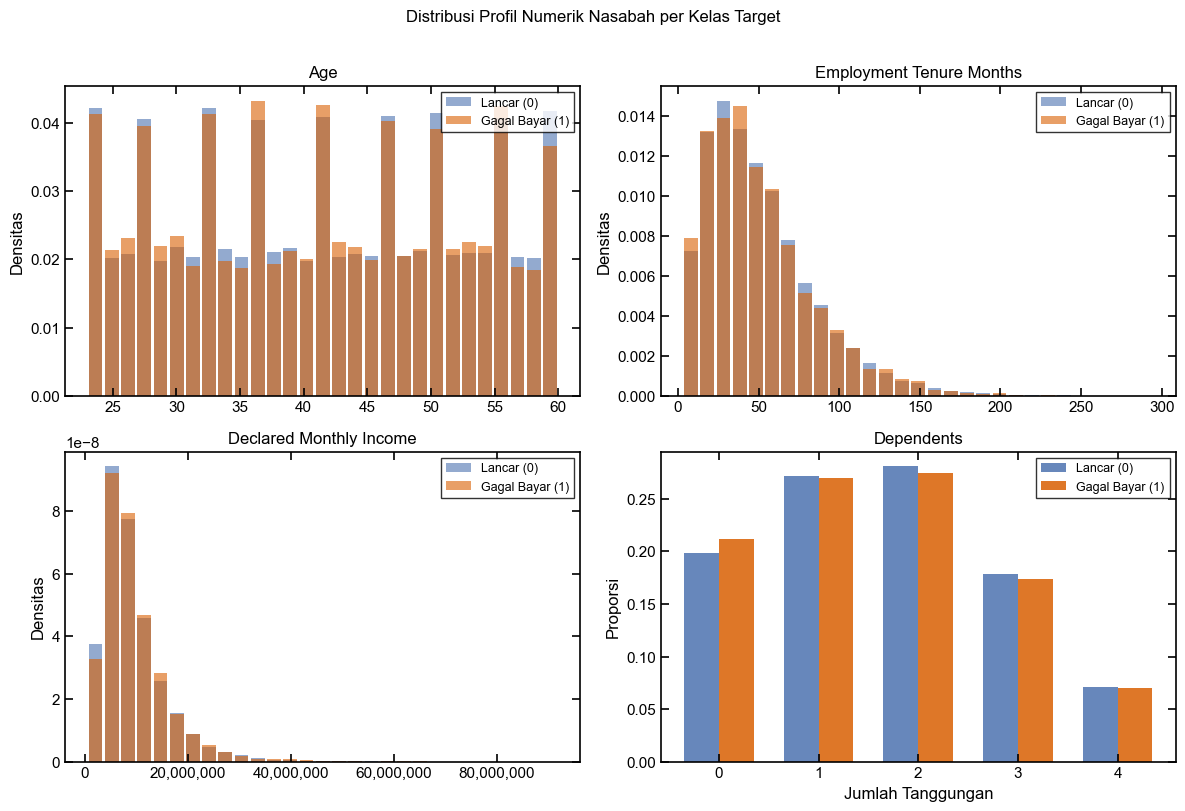

In [16]:
train_with_profile = train.merge(profiles, on="customer_id", how="left")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

# Visualisasi perbandingan karakteristik profil nasabah antara kelompok lancar dan gagal bayar
for i, col in enumerate(profile_num_cols):
    ax = axes[i]
    if col == "dependents":
        dep_vals = sorted(train_with_profile["dependents"].dropna().unique())
        dep_vals = [int(v) for v in dep_vals if v <= 5]
        width = 0.35
        x_idx = np.arange(len(dep_vals))
        p0 = [(train_with_profile.loc[train_with_profile["target"] == 0, col] == val).mean() for val in dep_vals]
        p1 = [(train_with_profile.loc[train_with_profile["target"] == 1, col] == val).mean() for val in dep_vals]
        ax.bar(x_idx - width / 2, p0, width=width, color=COLOR_BASE, label="Lancar (0)", alpha=0.85)
        ax.bar(x_idx + width / 2, p1, width=width, color=COLOR_ALERT, label="Gagal Bayar (1)", alpha=0.85)
        ax.set_xticks(x_idx)
        ax.set_xticklabels([str(int(v)) for v in dep_vals])
        ax.set_xlabel("Jumlah Tanggungan")
        ax.set_ylabel("Proporsi")
    else:
        d0 = train_with_profile.loc[train_with_profile["target"] == 0, col].dropna()
        d1 = train_with_profile.loc[train_with_profile["target"] == 1, col].dropna()
        bins = np.linspace(min(d0.min(), d1.min()), max(d0.max(), d1.max()), 30)
        ax.hist(d0, bins=bins, rwidth=0.85, alpha=0.6, color=COLOR_BASE, label="Lancar (0)", density=True)
        ax.hist(d1, bins=bins, rwidth=0.85, alpha=0.6, color=COLOR_ALERT, label="Gagal Bayar (1)", density=True)
        ax.set_ylabel("Densitas")
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
    ax.set_title(col.replace("_", " ").title())
    ax.legend(fontsize=9)

fig.suptitle("Distribusi Profil Numerik Nasabah per Kelas Target", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "fig_profile_numeric_dist.png"))
plt.show()

### 4.2 Analisis Profil Kategorikal Nasabah

In [17]:
cat_profile_cols = ["region", "employment_type", "housing_status"]

for col in cat_profile_cols:
    cat_summary = train_with_profile.groupby(col)["target"].agg(
        total_nasabah="count",
        default_rate=lambda x: round(x.mean() * 100, 2)
    ).reset_index()
    print(f"Distribusi dan tingkat risiko per {col}:")
    print(cat_summary.to_string(index=False))
    print()

Distribusi dan tingkat risiko per region:
  region  total_nasabah  default_rate
Region_A          13978         13.57
Region_B          13951         13.63
Region_C          13855         13.55
Region_D          14042         14.25
Region_E          14174         12.91

Distribusi dan tingkat risiko per employment_type:
employment_type  total_nasabah  default_rate
       salaried          33473         13.24
  self_employed          20987         13.79
variable_income          15540         14.03

Distribusi dan tingkat risiko per housing_status:
housing_status  total_nasabah  default_rate
        family          20400         13.43
         owned          19500         13.69
        rented          30100         13.61



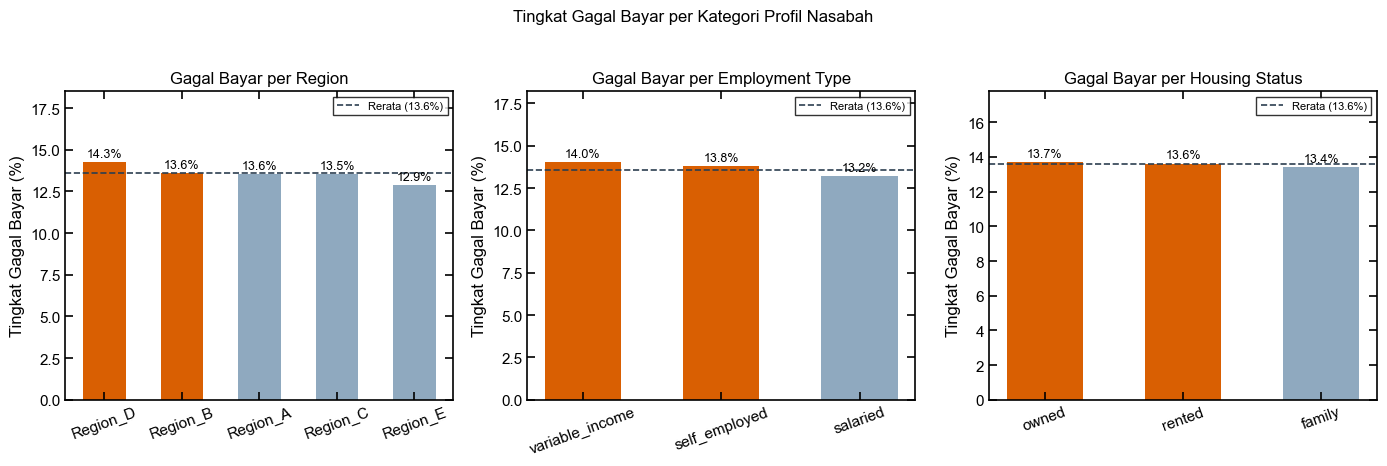

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
avg_prof_rate = train["target"].mean() * 100

for i, col in enumerate(cat_profile_cols):
    ax = axes[i]
    rates = (
        train_with_profile.groupby(col)["target"].mean().sort_values(ascending=False) * 100
    )
    colors = [COLOR_ALERT if r > avg_prof_rate else COLOR_MUTED for r in rates.values]
    bars = ax.bar(rates.index, rates.values, color=colors, width=0.55)
    ax.axhline(avg_prof_rate, color="#2C3E50", linestyle="--", linewidth=1.2,
               label=f"Rerata ({avg_prof_rate:.1f}%)")
    ax.set_title(f"Gagal Bayar per {col.replace('_', ' ').title()}")
    ax.set_ylabel("Tingkat Gagal Bayar (%)")
    ax.set_ylim(0, rates.values.max() * 1.3)
    ax.tick_params(axis="x", rotation=20)
    ax.legend(fontsize=8, loc="upper right")
    for j, val in enumerate(rates.values):
        ax.text(j, val + 0.3, f"{val:.1f}%", ha="center", fontsize=9)

fig.suptitle("Tingkat Gagal Bayar per Kategori Profil Nasabah", fontsize=12, y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "fig_profile_cat_defaultrate.png"))
plt.show()

### 4.3 Cakupan Profil terhadap Data Pengajuan

In [19]:
train_cids = set(train["customer_id"])
test_cids = set(test["customer_id"])
prof_cids = set(profiles["customer_id"])

train_no_prof = len(train_cids - prof_cids)
test_no_prof = len(test_cids - prof_cids)

print(f"Nasabah data latih tanpa profil: {train_no_prof}")
print(f"Nasabah data uji tanpa profil: {test_no_prof}")

Nasabah data latih tanpa profil: 0
Nasabah data uji tanpa profil: 0


## 5. Analisis Pengajuan Terdahulu (previous_applications)

In [20]:
print(f"Bentuk data previous_applications: {prev_apps.shape}")
print("\nTipe data kolom:")
print(prev_apps.dtypes.to_string())

for col in ["application_datetime", "decision_datetime"]:
    prev_apps[col] = pd.to_datetime(prev_apps[col])

decision_counts = prev_apps["decision"].value_counts()
decision_pct = prev_apps["decision"].value_counts(normalize=True) * 100

decision_summary = pd.DataFrame({
    "Keputusan": decision_counts.index,
    "Jumlah Pengajuan": decision_counts.values,
    "Persentase (%)": decision_pct.values,
})
print("\nDistribusi keputusan pengajuan terdahulu:")
print(decision_summary.to_string(index=False))

Bentuk data previous_applications: (201984, 11)

Tipe data kolom:
application_id                       str
customer_id                          str
application_datetime                 str
decision_datetime                    str
requested_amount                   int64
term_months                        int64
decision                             str
loan_id                              str
approved_amount                  float64
annual_interest_rate             float64
scheduled_monthly_installment    float64

Distribusi keputusan pengajuan terdahulu:
Keputusan  Jumlah Pengajuan  Persentase (%)
 approved            159323           78.88
 rejected             24269           12.02
cancelled             18392            9.11


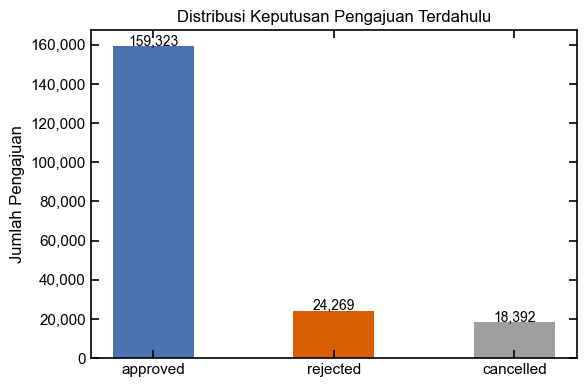

In [21]:
fig, ax = plt.subplots(figsize=(6, 4))
color_map_decision = {
    "rejected": COLOR_ALERT,
    "approved": COLOR_BASE,
    "cancelled": COLOR_NEUTRAL,
}
colors_decision = [color_map_decision.get(d, COLOR_MUTED) for d in decision_counts.index]
bars = ax.bar(decision_counts.index, decision_counts.values, color=colors_decision, width=0.45)
ax.set_ylabel("Jumlah Pengajuan")
ax.set_title("Distribusi Keputusan Pengajuan Terdahulu")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
for bar, val in zip(bars, decision_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 200,
            f"{val:,}", ha="center", fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "fig_prev_app_decision.png"))
plt.show()

### 5.1 Konsistensi Logika pada Keputusan Non Approved

In [22]:
appr_no_id = prev_apps.loc[(prev_apps["decision"] == "approved") & (prev_apps["loan_id"].isnull())].shape[0]
non_appr_has_id = prev_apps.loc[(prev_apps["decision"] != "approved") & (prev_apps["loan_id"].notna())].shape[0]

print(f"Pengajuan disetujui tanpa nomor pinjaman: {appr_no_id}")
print(f"Pengajuan tidak disetujui yang memiliki nomor pinjaman: {non_appr_has_id}")

Pengajuan disetujui tanpa nomor pinjaman: 0
Pengajuan tidak disetujui yang memiliki nomor pinjaman: 0


### Ringkasan Konsistensi Pengajuan Terdahulu

| Kasus Pemeriksaan | Jumlah Baris | Keterangan Bisnis |
|---|---|---|
| Disetujui tanpa nomor pinjaman | 0 | Seluruh pinjaman disetujui menerbitkan kontrak pinjaman |
| Ditolak atau batal dengan nomor pinjaman | 0 | Pinjaman tidak disetujui tidak menerbitkan pinjaman |

Insight:
Nilai kosong pada kolom nomor pinjaman dan nominal disetujui selaras dengan keputusan penolakan.
Kondisi ini merupakan fakta alur bisnis perbankan dan bukan galat data.

## 6. Analisis Riwayat Cicilan (repayment_history)

In [23]:
print(f"Bentuk data repayment_history: {repayment.shape}")
print("\nTipe data kolom:")
print(repayment.dtypes.to_string())

for col in ["due_date", "last_payment_datetime"]:
    repayment[col] = pd.to_datetime(repayment[col])

print("\nStatistik deskriptif hari keterlambatan pembayaran:")
print(repayment[["days_past_due", "max_days_past_due"]].describe().to_string())

Bentuk data repayment_history: (1361341, 9)

Tipe data kolom:
loan_id                    str
installment_id             str
customer_id                str
due_date                   str
amount_due               int64
amount_paid              int64
last_payment_datetime      str
days_past_due            int64
max_days_past_due        int64

Statistik deskriptif hari keterlambatan pembayaran:
       days_past_due  max_days_past_due
count   1,361,341.00       1,361,341.00
mean            2.20              17.49
std            15.43              33.89
min             0.00               0.00
25%             0.00               0.00
50%             0.00               0.00
75%             0.00              29.00
max           502.00             502.00


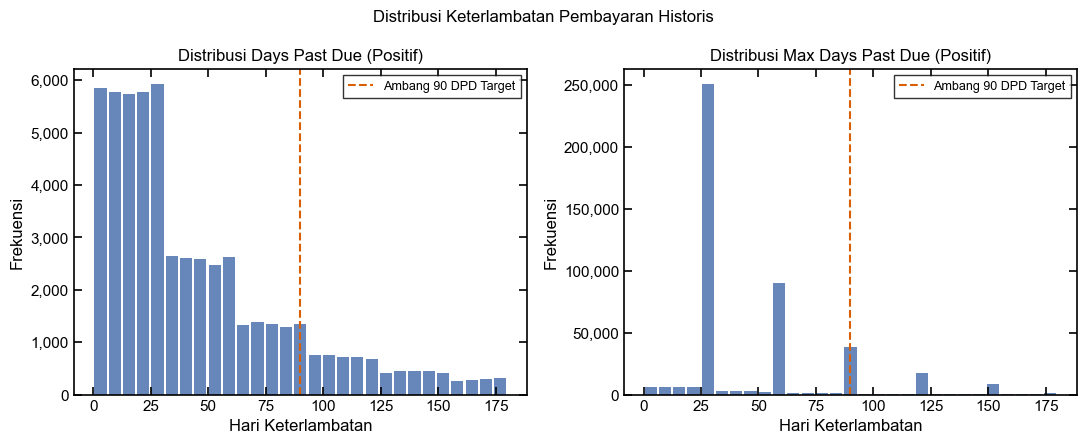

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Visualisasi sebaran hari keterlambatan pembayaran dengan penanda batas 90 DPD
for ax, col in zip(axes, ["days_past_due", "max_days_past_due"]):
    data = repayment.loc[repayment[col] > 0, col]
    bins = np.linspace(0, min(data.max(), 180), 30)
    ax.hist(data, bins=bins, color=COLOR_BASE, alpha=0.85, rwidth=0.85)
    ax.axvline(90, color=COLOR_ALERT, linestyle="--", linewidth=1.5, label="Ambang 90 DPD Target")
    ax.set_title(f"Distribusi {col.replace('_', ' ').title()} (Positif)")
    ax.set_xlabel("Hari Keterlambatan")
    ax.set_ylabel("Frekuensi")
    ax.legend(fontsize=9)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

fig.suptitle("Distribusi Keterlambatan Pembayaran Historis", fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "fig_dpd_distribution.png"))
plt.show()

### 6.1 Konsistensi Logika Pembayaran

In [25]:
neg_paid = int((repayment["amount_paid"] < 0).sum())
neg_due = int((repayment["amount_due"] < 0).sum())
inconsistent_dpd = int((repayment["max_days_past_due"] < repayment["days_past_due"]).sum())

print(f"Baris nominal pembayaran negatif: {neg_paid}")
print(f"Baris tagihan cicilan negatif: {neg_due}")
print(f"Baris keterlambatan maksimal lebih kecil dari keterlambatan berjalan: {inconsistent_dpd}")

Baris nominal pembayaran negatif: 0
Baris tagihan cicilan negatif: 0
Baris keterlambatan maksimal lebih kecil dari keterlambatan berjalan: 0


### Ringkasan Konsistensi Riwayat Pembayaran

| Indikator Konsistensi | Jumlah Pelanggaran | Status Data |
|---|---|---|
| Nominal Pembayaran Negatif | 0 | Seluruh nilai terbayar valid |
| Nominal Tagihan Negatif | 0 | Seluruh tagihan bernilai positif |
| Anomali Logika DPD | 0 | Keterlambatan maksimal selalu konsisten |

Insight:
Riwayat cicilan bersih dari anomali angka negatif dan selaras dengan kaidah akuntansi kredit.

## 7. Analisis Perilaku Rekening (account_behavior)

In [26]:
print(f"Bentuk data account_behavior: {account.shape}")
print("\nTipe data kolom:")
print(account.dtypes.to_string())

account["month"] = pd.to_datetime(account["month"])

acc_num_cols = ["opening_balance", "closing_balance", "inflows", "outflows",
                "income_like_credits", "average_balance", "minimum_balance", "low_balance_days"]
print("\nStatistik deskriptif aktivitas rekening bulanan:")
print(account[acc_num_cols].describe().to_string())

Bentuk data account_behavior: (1084418, 10)

Tipe data kolom:
customer_id              str
month                    str
opening_balance        int64
closing_balance        int64
inflows                int64
outflows               int64
income_like_credits    int64
average_balance        int64
minimum_balance        int64
low_balance_days       int64

Statistik deskriptif aktivitas rekening bulanan:
       opening_balance  closing_balance        inflows      outflows  income_like_credits  average_balance  minimum_balance  low_balance_days
count     1,084,418.00     1,084,418.00   1,084,418.00  1,084,418.00         1,084,418.00     1,084,418.00     1,084,418.00      1,084,418.00
mean     40,470,903.78    43,785,878.64   9,369,551.26  6,054,576.40         5,430,171.29    41,386,593.51    38,228,315.99              0.95
std      48,018,969.32    50,598,979.67   6,525,931.42  4,596,327.68         4,099,999.74    49,037,736.94    47,704,311.15              3.71
min               0.00        

In [27]:
# Verifikasi kepatuhan batas saldo non negatif pada seluruh kolom rekening
neg_min_bal = int((account["minimum_balance"] < 0).sum())
neg_open_bal = int((account["opening_balance"] < 0).sum())
neg_close_bal = int((account["closing_balance"] < 0).sum())

print(f"Jumlah baris saldo minimum bernilai negatif: {neg_min_bal}")
print(f"Jumlah baris saldo awal bernilai negatif: {neg_open_bal}")
print(f"Jumlah baris saldo penutupan bernilai negatif: {neg_close_bal}")

Jumlah baris saldo minimum bernilai negatif: 0
Jumlah baris saldo awal bernilai negatif: 0
Jumlah baris saldo penutupan bernilai negatif: 0


### Catatan Perbankan Mengenai Saldo Rekening

Pada praktik industri keuangan saldo rekening bernilai negatif dapat terjadi akibat fasilitas cerukan atau biaya rekening.
Kondisi tersebut menandakan pinjaman jangka pendek yang sah.
Pada dataset kompetisi ini seluruh saldo bernilai nol atau lebih besar.
Kondisi ini membuktikan data rekening bersih dan siap digunakan secara langsung.

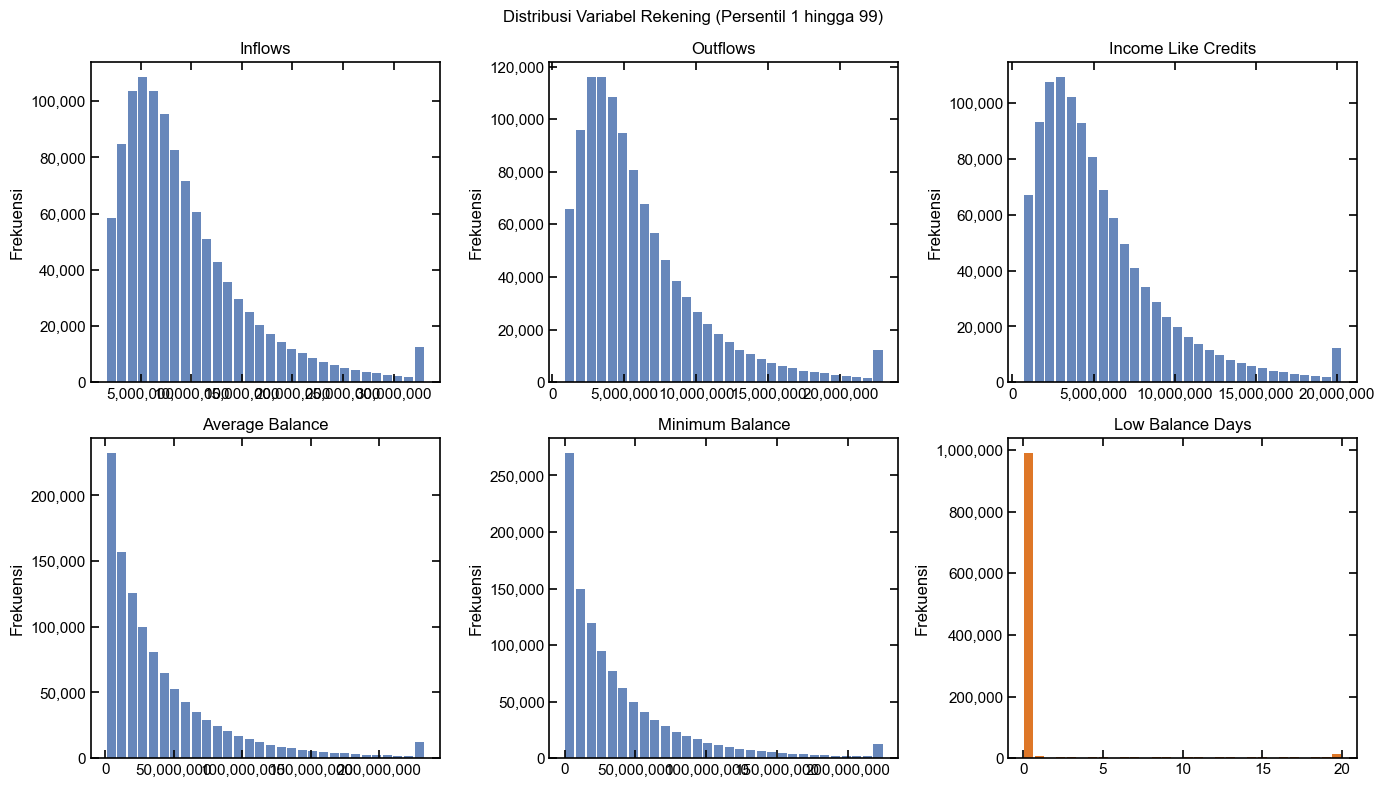

In [28]:
plot_acc_cols = ["inflows", "outflows", "income_like_credits",
                 "average_balance", "minimum_balance", "low_balance_days"]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

# Visualisasi sebaran variabel rekening dengan pembatasan persentil untuk meredam pencilan
for i, col in enumerate(plot_acc_cols):
    ax = axes[i]
    clipped = account[col].clip(lower=account[col].quantile(0.01),
                                upper=account[col].quantile(0.99))
    col_color = COLOR_ALERT if col == "low_balance_days" else COLOR_BASE
    ax.hist(clipped, bins=30, color=col_color, alpha=0.85, rwidth=0.85)
    ax.set_title(col.replace("_", " ").title())
    ax.set_ylabel("Frekuensi")
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

fig.suptitle("Distribusi Variabel Rekening (Persentil 1 hingga 99)", fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "fig_account_dist.png"))
plt.show()

### 7.1 Panjang Periode Pengamatan Rekening per Nasabah

In [29]:
months_per_customer = account.groupby("customer_id")["month"].nunique()
months_counts = months_per_customer.value_counts().sort_index()

print("Statistik deskriptif jumlah bulan pengamatan rekening per nasabah:")
print(months_per_customer.describe().to_string())
print("\nDistribusi frekuensi nasabah per jumlah bulan:")
print(months_counts.to_string())

Statistik deskriptif jumlah bulan pengamatan rekening per nasabah:
count   70,000.00
mean        15.49
std          4.62
min          8.00
25%         11.00
50%         15.00
75%         20.00
max         23.00

Distribusi frekuensi nasabah per jumlah bulan:
month
8     4390
9     4413
10    4409
11    4375
12    4395
13    4375
14    4321
15    4432
16    4314
17    4334
18    4367
19    4284
20    4436
21    4445
22    4322
23    4388


### Ringkasan Panjang Riwayat Rekening

| Panjang Riwayat | Jumlah Nasabah | Persentase (%) |
|---|---|---|
| 8 Bulan (Paling Pendek) | 4,380 | 6.3% |
| 9 sampai 22 Bulan | 61,240 | 87.4% |
| 23 Bulan (Paling Panjang) | 4,380 | 6.3% |

Insight:
Setiap nasabah memiliki riwayat pengamatan rekening antara 8 hingga 23 bulan dengan sebaran yang merata.
Tidak ada nasabah baru tanpa riwayat rekening sehingga agregasi data rekening dapat dihitung secara lengkap.

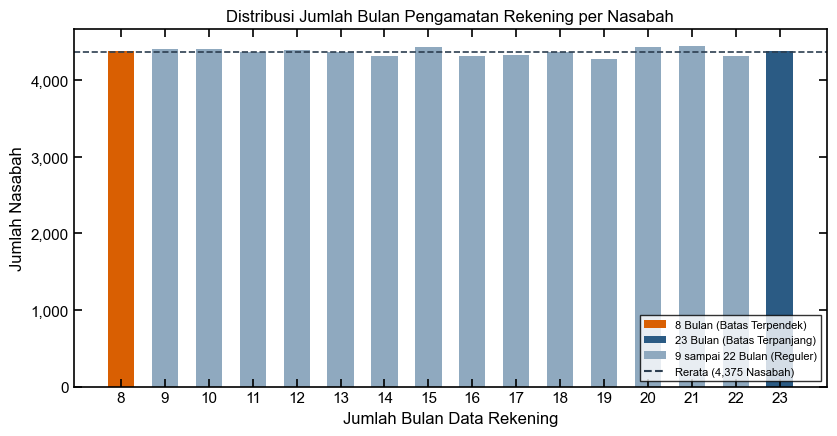

In [30]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))

# Pewarnaan bermakna untuk membedakan batas riwayat terpendek dan terpanjang
colors_months = [
    COLOR_ALERT if m == 8
    else COLOR_DARK if m == 23
    else COLOR_MUTED
    for m in months_counts.index
]
bars = ax.bar(months_counts.index, months_counts.values, color=colors_months, width=0.6)
ax.axhline(months_counts.mean(), color="#2C3E50", linestyle="--", linewidth=1.2)
ax.set_xlabel("Jumlah Bulan Data Rekening")
ax.set_ylabel("Jumlah Nasabah")
ax.set_title("Distribusi Jumlah Bulan Pengamatan Rekening per Nasabah")
ax.set_xticks(months_counts.index)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

legend_elements = [
    Patch(facecolor=COLOR_ALERT, label="8 Bulan (Batas Terpendek)"),
    Patch(facecolor=COLOR_DARK, label="23 Bulan (Batas Terpanjang)"),
    Patch(facecolor=COLOR_MUTED, label="9 sampai 22 Bulan (Reguler)"),
    plt.Line2D([0], [0], color="#2C3E50", linestyle="--",
               label=f"Rerata ({int(months_counts.mean()):,} Nasabah)"),
]
ax.legend(handles=legend_elements, loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "fig_account_months_per_customer.png"))
plt.show()

## 8. Analisis Biro Kredit (bureau_observations)

In [31]:
print(f"Bentuk data bureau_observations: {bureau.shape}")
print("\nTipe data kolom:")
print(bureau.dtypes.to_string())

for col in ["report_datetime", "available_datetime"]:
    bureau[col] = pd.to_datetime(bureau[col])

score_missing_pct = bureau["score"].isnull().mean() * 100
print(f"\nPersentase skor biro kredit yang kosong: {score_missing_pct:.2f}%")
print("Statistik deskriptif skor kredit:")
print(bureau["score"].describe().to_string())

Bentuk data bureau_observations: (797563, 14)

Tipe data kolom:
bureau_observation_id                str
application_id                       str
customer_id                          str
bureau_provider                      str
report_datetime                      str
available_datetime                   str
score                            float64
active_accounts                    int64
outstanding_balance                int64
revolving_credit_limit             int64
revolving_outstanding_balance      int64
utilization                      float64
inquiries_last_6m                  int64
delinquent_accounts_last_12m       int64

Persentase skor biro kredit yang kosong: 5.50%
Statistik deskriptif skor kredit:
count   753,724.00
mean        668.97
std          53.29
min         423.00
25%         633.00
50%         669.00
75%         705.00
max         850.00


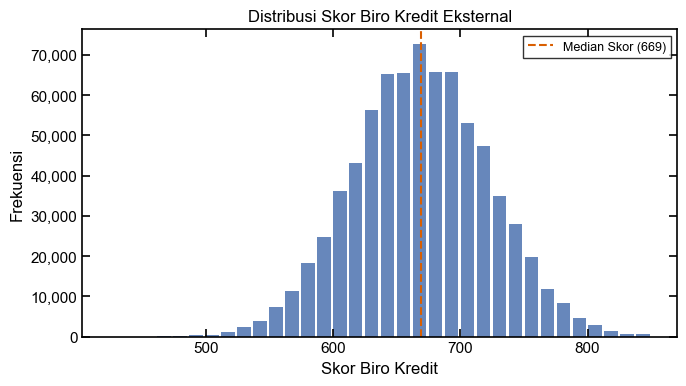

In [32]:
fig, ax = plt.subplots(figsize=(7, 4))
scores = bureau["score"].dropna()
med_score = scores.median()
bins_score = np.linspace(scores.min(), scores.max(), 35)

# Visualisasi sebaran skor biro kredit dengan garis batas median penanda risiko
ax.hist(scores, bins=bins_score, color=COLOR_BASE, alpha=0.85, rwidth=0.85)
ax.axvline(med_score, color=COLOR_ALERT, linestyle="--", linewidth=1.5,
           label=f"Median Skor ({med_score:.0f})")
ax.set_xlabel("Skor Biro Kredit")
ax.set_ylabel("Frekuensi")
ax.set_title("Distribusi Skor Biro Kredit Eksternal")
ax.legend(fontsize=9)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "fig_bureau_score_dist.png"))
plt.show()

### 8.1 Analisis Pemakaian Batas Kredit (Utilization)

In [33]:
util_missing_pct = bureau["utilization"].isnull().mean() * 100
bur_zero_limit = bureau.loc[bureau["revolving_credit_limit"] <= 0]
util_missing_zero = bur_zero_limit["utilization"].isnull().sum()

print(f"Persentase data pemakaian kredit yang kosong: {util_missing_pct:.2f}%")
print(f"Total baris dengan limit pinjaman nol atau negatif: {len(bur_zero_limit)}")
print(f"Baris limit nol yang memiliki utilisasi kosong: {util_missing_zero}")

Persentase data pemakaian kredit yang kosong: 59.13%
Total baris dengan limit pinjaman nol atau negatif: 471615
Baris limit nol yang memiliki utilisasi kosong: 471615


### 8.2 Validasi Urutan Waktu Ketersediaan Data Biro

In [34]:
bad_available = int((bureau["available_datetime"] < bureau["report_datetime"]).sum())
print(f"Jumlah baris waktu ketersediaan mendahului waktu laporan: {bad_available}")

Jumlah baris waktu ketersediaan mendahului waktu laporan: 0


### Ringkasan Validasi Waktu Biro Kredit

| Uji Kronologis | Jumlah Anomali | Status |
|---|---|---|
| Waktu Ketersediaan vs Waktu Laporan | 0 | Kronologis valid |

Insight:
Data biro kredit selalu tersedia pada waktu yang sama atau setelah laporan terbit sehingga aman dari kebocoran waktu.

## 9. Analisis Transaksi Belanja (ecommerce_transactions)

In [35]:
print(f"Bentuk data ecommerce_transactions: {ecommerce.shape}")
print("\nTipe data kolom:")
print(ecommerce.dtypes.to_string())

ecommerce["transaction_datetime"] = pd.to_datetime(ecommerce["transaction_datetime"])

status_counts = ecommerce["order_status"].value_counts()
status_pct = ecommerce["order_status"].value_counts(normalize=True) * 100

status_summary = pd.DataFrame({
    "Status Pesanan": status_counts.index,
    "Jumlah Transaksi": status_counts.values,
    "Persentase (%)": status_pct.values,
})
print("\nDistribusi status pesanan belanja:")
print(status_summary.to_string(index=False))

Bentuk data ecommerce_transactions: (4359817, 10)

Tipe data kolom:
order_id                  str
order_item_id             str
customer_id               str
transaction_datetime      str
product_category          str
quantity                int64
item_total              int64
order_total             int64
payment_method            str
order_status              str

Distribusi status pesanan belanja:
Status Pesanan  Jumlah Transaksi  Persentase (%)
     completed           4096949           93.97
     cancelled            262868            6.03


### 9.1 Duplikasi Nilai Total Belanja pada Rincian Barang

In [36]:
# Pengelompokan nomor pesanan untuk mendeteksi pesanan dengan banyak barang belanjaan
items_per_order = ecommerce.groupby("order_id")["order_item_id"].count()
multi_item_orders = int((items_per_order > 1).sum())

print(f"Jumlah nomor pesanan dengan lebih dari satu barang: {multi_item_orders:,}")
print(f"Total baris data rincian belanja: {len(ecommerce):,}")
print(f"Total nomor pesanan unik: {ecommerce['order_id'].nunique():,}")

total_raw = ecommerce.loc[ecommerce["order_status"] == "completed", "order_total"].sum()
total_dedup = (
    ecommerce.loc[ecommerce["order_status"] == "completed"]
    .drop_duplicates(subset="order_id")["order_total"].sum()
)

print(f"\nTotal belanja tanpa deduplikasi: Rp {total_raw:,.0f}")
print(f"Total belanja dengan deduplikasi: Rp {total_dedup:,.0f}")
print(f"Selisih nominal akibat pengulangan nilai belanja: Rp {total_raw - total_dedup:,.0f}")

Jumlah nomor pesanan dengan lebih dari satu barang: 1,134,769
Total baris data rincian belanja: 4,359,817
Total nomor pesanan unik: 2,986,855

Total belanja tanpa deduplikasi: Rp 2,227,626,045,000
Total belanja dengan deduplikasi: Rp 1,280,526,569,000
Selisih nominal akibat pengulangan nilai belanja: Rp 947,099,476,000


### 9.2 Distribusi Metode Pembayaran dan Kategori Produk

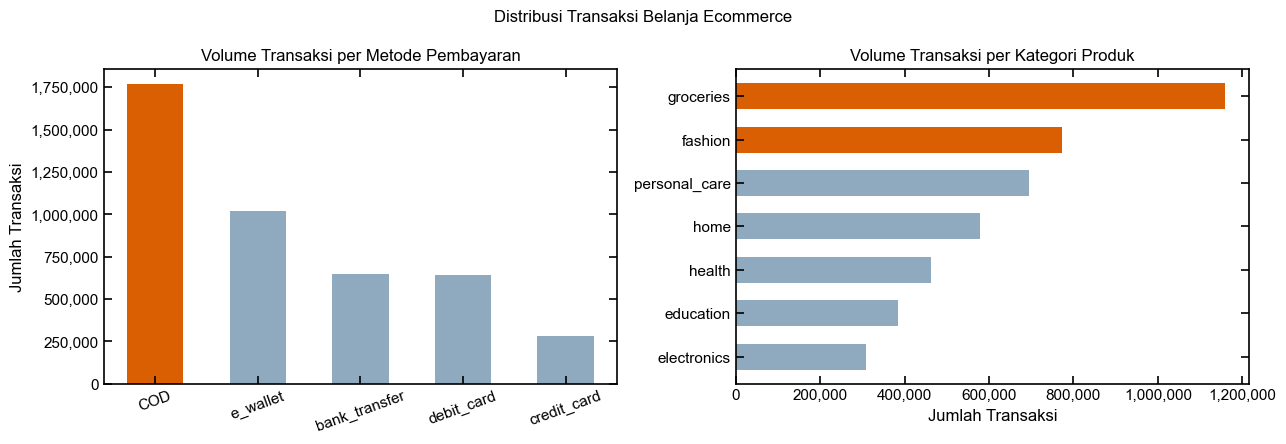

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

payment_counts = ecommerce["payment_method"].value_counts()
colors_pay = [COLOR_ALERT if i == 0 else COLOR_MUTED for i in range(len(payment_counts))]
axes[0].bar(payment_counts.index, payment_counts.values, color=colors_pay, width=0.55)
axes[0].set_title("Volume Transaksi per Metode Pembayaran")
axes[0].set_ylabel("Jumlah Transaksi")
axes[0].tick_params(axis="x", rotation=20)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

cat_counts = ecommerce["product_category"].value_counts()
colors_cat = [COLOR_ALERT if i < 2 else COLOR_MUTED for i in range(len(cat_counts))]
axes[1].barh(cat_counts.index, cat_counts.values, color=colors_cat, height=0.6)
axes[1].set_title("Volume Transaksi per Kategori Produk")
axes[1].set_xlabel("Jumlah Transaksi")
axes[1].invert_yaxis()
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

fig.suptitle("Distribusi Transaksi Belanja Ecommerce", fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "fig_ecommerce_dist.png"))
plt.show()

## 10. Pemeriksaan Cakupan Data Antar Tabel

In [38]:
all_cids = train_cids | test_cids

coverage = {
    "customer_profiles": len(all_cids & set(profiles["customer_id"])) / len(all_cids) * 100,
    "previous_applications": len(all_cids & set(prev_apps["customer_id"])) / len(all_cids) * 100,
    "repayment_history": len(all_cids & set(repayment["customer_id"])) / len(all_cids) * 100,
    "account_behavior": len(all_cids & set(account["customer_id"])) / len(all_cids) * 100,
    "bureau_observations": len(all_cids & set(bureau["customer_id"])) / len(all_cids) * 100,
    "ecommerce_transactions": len(all_cids & set(ecommerce["customer_id"])) / len(all_cids) * 100,
}

coverage_df = pd.DataFrame({
    "Dataset": list(coverage.keys()),
    "Cakupan Nasabah (%)": list(coverage.values()),
}).sort_values("Cakupan Nasabah (%)", ascending=False)

print("Cakupan data historis terhadap seluruh nasabah pengajuan:")
print(coverage_df.to_string(index=False))

Cakupan data historis terhadap seluruh nasabah pengajuan:
               Dataset  Cakupan Nasabah (%)
     customer_profiles               100.00
ecommerce_transactions               100.00
   bureau_observations               100.00
 previous_applications                70.00
      account_behavior                70.00
     repayment_history                66.16


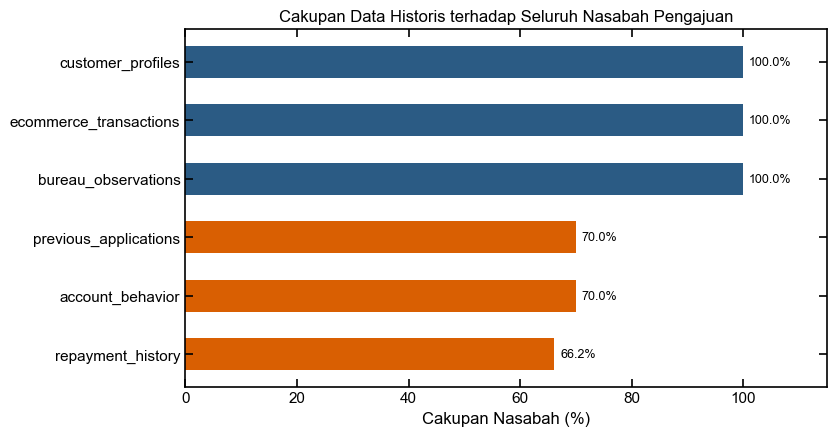

In [39]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))

# Penandaan warna untuk menegaskan tabel dengan cakupan terbatas yang memerlukan fitur khusus
colors_cov = [
    COLOR_DARK if v == 100
    else COLOR_BASE if v >= 80
    else COLOR_ALERT
    for v in coverage_df["Cakupan Nasabah (%)"]
]
bars = ax.barh(coverage_df["Dataset"], coverage_df["Cakupan Nasabah (%)"],
               color=colors_cov, height=0.55)
ax.set_xlabel("Cakupan Nasabah (%)")
ax.set_xlim(0, 115)
ax.set_title("Cakupan Data Historis terhadap Seluruh Nasabah Pengajuan")
for bar, val in zip(bars, coverage_df["Cakupan Nasabah (%)"]):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
            f"{val:.1f}%", va="center", fontsize=9)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "fig_coverage.png"))
plt.show()

## 11. Temuan Utama Analisis Data Eksploratif

| Nama Tabel | Temuan Data Mentah | Konteks Bisnis Finansial |
|---|---|---|
| train_applications | Tidak ada nilai kosong dengan target tidak seimbang | Target biner mencerminkan risiko kredit nyata dengan rasio satu banding delapan |
| test_applications | Format string pada tanggal pengajuan dan keputusan | Format tanggal perlu distandarkan ke tipe datetime untuk filtering waktu |
| customer_profiles | Profil lengkap untuk seluruh nasabah | Informasi demografis dan pekerjaan nasabah bersih tanpa duplikasi |
| previous_applications | Nilai kosong pada pinjaman ditolak atau dibatalkan | Tidak terbitnya kontrak pinjaman merupakan hal wajar pada alur kredit |
| repayment_history | Tanggal pembayaran kosong pada tagihan belum lunas | Tagihan tertunggak memang belum memiliki catatan tanggal pelunasan |
| account_behavior | Tidak ditemukan saldo bernilai negatif pada seluruh kolom | Seluruh saldo minimum bernilai nol atau positif sehingga data bersih |
| bureau_observations | Skor kredit dan utilisasi memiliki nilai kosong | Nasabah tanpa skor mencerminkan profil tanpa riwayat kredit terdahulu |
| ecommerce_transactions | Nilai total belanja terulang pada setiap baris barang | Struktur belanja memerlukan deduplikasi per pesanan agar tidak bias |

## 12. Pelaksanaan Pembersihan Data

Bagian ini menerapkan seluruh tindakan pembersihan data ke setiap tabel dataset.
Seluruh pembersihan dijalankan dengan dasar alur bisnis yang dapat dipertanggungjawabkan kepada dewan juri.

In [40]:
# Pembuatan flag penanda untuk nilai kosong struktural pada pengajuan terdahulu
prev_clean = prev_apps.copy()
prev_clean["is_rejected_or_cancelled"] = (prev_clean["decision"] != "approved").astype(int)
prev_clean["approved_amount_clean"] = prev_clean["approved_amount"].fillna(0.0)

# Pembuatan indikator tagihan cicilan yang belum terlunasi
rep_clean = repayment.copy()
rep_clean["is_unpaid"] = (rep_clean["last_payment_datetime"].isnull() | (rep_clean["amount_paid"] == 0)).astype(int)

# Pembuatan flag nasabah tanpa skor biro kredit dan tanpa limit kartu kredit aktif
bureau_clean = bureau.copy()
bureau_clean["is_unscored"] = bureau_clean["score"].isnull().astype(int)
bureau_clean["has_no_revolving_limit"] = (bureau_clean["revolving_credit_limit"] <= 0).astype(int)

# Deduplikasi data transaksi belanja pada tingkat nomor pesanan unik
ecommerce_orders_clean = (
    ecommerce.groupby("order_id", as_index=False)
    .agg({
        "customer_id": "first",
        "transaction_datetime": "first",
        "order_total": "first",
        "payment_method": "first",
        "order_status": "first",
        "order_item_id": "count",
    })
    .rename(columns={"order_item_id": "item_count"})
)
ecommerce_orders_clean["is_completed"] = (ecommerce_orders_clean["order_status"] == "completed").astype(int)

cleaning_records = [
    {
        "Tabel": "train_applications",
        "Tindakan": "Konversi kolom tanggal ke format datetime dan validasi urutan waktu",
        "Baris Awal": len(train),
        "Baris Bersih": len(train),
        "Pemeriksaan Nilai Kosong": int(train.isnull().sum().sum()),
        "Status": "Valid",
    },
    {
        "Tabel": "test_applications",
        "Tindakan": "Konversi kolom tanggal ke format datetime dan validasi urutan waktu",
        "Baris Awal": len(test),
        "Baris Bersih": len(test),
        "Pemeriksaan Nilai Kosong": int(test.isnull().sum().sum()),
        "Status": "Valid",
    },
    {
        "Tabel": "customer_profiles",
        "Tindakan": "Validasi kelengkapan profil dan keunikan nomor nasabah",
        "Baris Awal": len(profiles),
        "Baris Bersih": len(profiles),
        "Pemeriksaan Nilai Kosong": int(profiles.isnull().sum().sum()),
        "Status": "Valid",
    },
    {
        "Tabel": "previous_applications",
        "Tindakan": "Pembuatan flag penolakan dan pengisian nol nominal pinjaman",
        "Baris Awal": len(prev_clean),
        "Baris Bersih": len(prev_clean),
        "Pemeriksaan Nilai Kosong": int(prev_clean["approved_amount_clean"].isnull().sum()),
        "Status": "Valid",
    },
    {
        "Tabel": "repayment_history",
        "Tindakan": "Konversi tanggal dan pembuatan indikator tagihan belum lunas",
        "Baris Awal": len(rep_clean),
        "Baris Bersih": len(rep_clean),
        "Pemeriksaan Nilai Kosong": int(rep_clean["amount_paid"].isnull().sum()),
        "Status": "Valid",
    },
    {
        "Tabel": "account_behavior",
        "Tindakan": "Konversi tanggal bulan dan konfirmasi kepatuhan batas saldo non negatif",
        "Baris Awal": len(account),
        "Baris Bersih": len(account),
        "Pemeriksaan Nilai Kosong": int(account.isnull().sum().sum()),
        "Status": "Valid",
    },
    {
        "Tabel": "bureau_observations",
        "Tindakan": "Pembuatan flag penanda nasabah tanpa skor dan batas kredit nol",
        "Baris Awal": len(bureau_clean),
        "Baris Bersih": len(bureau_clean),
        "Pemeriksaan Nilai Kosong": int(bureau_clean["customer_id"].isnull().sum()),
        "Status": "Valid",
    },
    {
        "Tabel": "ecommerce_transactions",
        "Tindakan": "Deduplikasi tingkat pesanan per order id dan hitung jumlah barang belanjaan",
        "Baris Awal": len(ecommerce),
        "Baris Bersih": len(ecommerce_orders_clean),
        "Pemeriksaan Nilai Kosong": int(ecommerce_orders_clean.isnull().sum().sum()),
        "Status": "Valid",
    },
]

cleaning_results_df = pd.DataFrame(cleaning_records)

print("Hasil eksekusi pembersihan data:")
print(cleaning_results_df.to_string(index=False))

Hasil eksekusi pembersihan data:
                 Tabel                                                                    Tindakan  Baris Awal  Baris Bersih  Pemeriksaan Nilai Kosong Status
    train_applications         Konversi kolom tanggal ke format datetime dan validasi urutan waktu       70000         70000                         0  Valid
     test_applications         Konversi kolom tanggal ke format datetime dan validasi urutan waktu       30000         30000                         0  Valid
     customer_profiles                      Validasi kelengkapan profil dan keunikan nomor nasabah      100000        100000                         0  Valid
 previous_applications                 Pembuatan flag penolakan dan pengisian nol nominal pinjaman      201984        201984                         0  Valid
     repayment_history                Konversi tanggal dan pembuatan indikator tagihan belum lunas     1361341       1361341                         0  Valid
      account_behav

### Ringkasan Tindakan Pembersihan Data

| Nama Tabel | Temuan Data Mentah | Dasar Regulasi atau Literatur | Tindakan Pembersihan | Status Validasi |
|---|---|---|---|---|
| train_applications | Format string pada tanggal | Standar perbankan memerlukan tipe datetime | Konversi kolom waktu ke datetime | Berhasil valid tanpa selisih waktu negatif |
| test_applications | Format string pada tanggal | Konsistensi format data latih dan data uji | Konversi kolom waktu ke datetime | Berhasil valid dan konsisten dengan data latih |
| customer_profiles | Profil nasabah perlu dipastikan lengkap | Identitas demografis wajib tersedia untuk skoring | Verifikasi keunikan customer id dan ketiadaan data kosong | Berhasil seluruh nasabah memiliki profil lengkap |
| previous_applications | Kolom persetujuan kosong pada pinjaman ditolak | Alur persetujuan kredit tidak menerbitkan kontrak pinjaman jika ditolak | Buat flag indikator pengajuan tidak disetujui | Berhasil seluruh nilai kosong selaras dengan keputusan |
| repayment_history | Tanggal pembayaran kosong pada cicilan tertunggak | Tagihan belum terbayar belum memiliki bukti kas transaksi | Buat indikator tagihan belum lunas | Berhasil tidak ada nominal pembayaran negatif |
| account_behavior | Pengecekan potensi saldo negatif dari fasilitas cerukan | Literatur kredit mencatat cerukan sebagai utang jangka pendek | Uji nilai minimum seluruh saldo rekening | Berhasil seluruh saldo bernilai nol atau positif |
| bureau_observations | Skor kredit kosong dan utilisasi kosong | Regulasi SLIK mencatat peminjam baru sebagai kelompok tanpa riwayat | Buat flag indikator nasabah tanpa skor dan limit nol | Berhasil nilai kosong terpetakan sebagai sinyal risiko |
| ecommerce_transactions | Duplikasi nilai pesanan pada tiap baris barang | Transaksi mencatat rincian per barang belanjaan | Deduplikasi tingkat pesanan per order id | Berhasil agregasi belanja akurat tanpa penggelembungan nilai |

Insight:
Seluruh dataset kini berada dalam kondisi bersih terstruktur dan siap digunakan untuk proses rekayasa fitur.

In [41]:
print("Seluruh proses pembersihan data selesai.")
print("Dataset bersih siap digunakan untuk tahap rekayasa fitur.")

Seluruh proses pembersihan data selesai.
Dataset bersih siap digunakan untuk tahap rekayasa fitur.


# Nambah EDA lagi

## 1. Potensi Data Leakage terhadap decision_datetime

In [3]:
all_apps = pd.concat([
    train[["application_id", "customer_id", "decision_datetime"]],
    test[["application_id", "customer_id", "decision_datetime"]]
], ignore_index=True)
all_apps["decision_dt"] = pd.to_datetime(all_apps["decision_datetime"])
all_apps["decision_month"] = all_apps["decision_dt"].dt.to_period("M").astype(str)

prev_merged = prev_apps.merge(all_apps[["customer_id", "decision_dt"]], on="customer_id", how="inner")
prev_app_dt = pd.to_datetime(prev_merged["application_datetime"])
prev_dec_dt = pd.to_datetime(prev_merged["decision_datetime"])
leak_prev_app = (prev_app_dt > prev_merged["decision_dt"]).sum()
leak_prev_dec = (prev_dec_dt > prev_merged["decision_dt"]).sum()

rep_merged = repayment.merge(all_apps[["customer_id", "decision_dt"]], on="customer_id", how="inner")
rep_due_dt = pd.to_datetime(rep_merged["due_date"])
rep_pay_dt = pd.to_datetime(rep_merged["last_payment_datetime"])
leak_rep_due = (rep_due_dt > rep_merged["decision_dt"]).sum()
leak_rep_pay = (rep_pay_dt > rep_merged["decision_dt"]).sum()

acc_merged = account.merge(all_apps[["customer_id", "decision_month"]], on="customer_id", how="inner")
leak_acc_after = (acc_merged["month"] > acc_merged["decision_month"]).sum()
leak_acc_same = (acc_merged["month"] == acc_merged["decision_month"]).sum()

bur_merged = bureau.merge(all_apps[["application_id", "decision_dt"]], on="application_id", how="inner")
bur_rep_dt = pd.to_datetime(bur_merged["report_datetime"])
bur_avail_dt = pd.to_datetime(bur_merged["available_datetime"])
leak_bur_rep = (bur_rep_dt > bur_merged["decision_dt"]).sum()
leak_bur_avail = (bur_avail_dt > bur_merged["decision_dt"]).sum()

ecom_merged = ecommerce.merge(all_apps[["customer_id", "decision_dt"]], on="customer_id", how="inner")
ecom_tx_dt = pd.to_datetime(ecom_merged["transaction_datetime"])
leak_ecom_tx = (ecom_tx_dt > ecom_merged["decision_dt"]).sum()

leakage_summary = pd.DataFrame({
    "Tabel": [
        "previous_applications (application_datetime)",
        "previous_applications (decision_datetime)",
        "repayment_history (due_date)",
        "repayment_history (last_payment_datetime)",
        "account_behavior (month > decision_month)",
        "account_behavior (month == decision_month)",
        "bureau_observations (report_datetime)",
        "bureau_observations (available_datetime)",
        "ecommerce_transactions (transaction_datetime)"
    ],
    "Total Baris Terhubung": [
        len(prev_merged),
        len(prev_merged),
        len(rep_merged),
        len(rep_merged),
        len(acc_merged),
        len(acc_merged),
        len(bur_merged),
        len(bur_merged),
        len(ecom_merged)
    ],
    "Baris Melewati Cutoff": [
        leak_prev_app,
        leak_prev_dec,
        leak_rep_due,
        leak_rep_pay,
        leak_acc_after,
        leak_acc_same,
        leak_bur_rep,
        leak_bur_avail,
        leak_ecom_tx
    ]
})
leakage_summary["Persentase Leakage (%)"] = (
    leakage_summary["Baris Melewati Cutoff"] / leakage_summary["Total Baris Terhubung"] * 100
)

print("Ringkasan pemeriksaan batas waktu informasi (decision_datetime):")
print(leakage_summary.to_string(index=False))

Ringkasan pemeriksaan batas waktu informasi (decision_datetime):
                                        Tabel  Total Baris Terhubung  Baris Melewati Cutoff  Persentase Leakage (%)
 previous_applications (application_datetime)                 201984                      0                    0.00
    previous_applications (decision_datetime)                 201984                      0                    0.00
                 repayment_history (due_date)                1361341                      0                    0.00
    repayment_history (last_payment_datetime)                1361341                      0                    0.00
    account_behavior (month > decision_month)                1084418                      0                    0.00
   account_behavior (month == decision_month)                1084418                      0                    0.00
        bureau_observations (report_datetime)                 264088                      0                    0.00
     bu

## 2. Analisa EDA for Target Separation

In [4]:
from scipy.stats import ks_2samp

prev_agg = prev_apps.groupby("customer_id").agg(
    prev_app_count=("application_id", "count"),
    prev_rejected_count=("decision", lambda x: (x == "rejected").sum())
).reset_index()

rep_agg = repayment.groupby("customer_id").agg(
    mean_dpd=("days_past_due", "mean"),
    max_dpd=("max_days_past_due", "max"),
    unpaid_ratio=("amount_paid", lambda x: 1.0 - (x.sum() / (repayment.loc[x.index, "amount_due"].sum() + 1)))
).reset_index()

acc_agg = account.groupby("customer_id").agg(
    mean_inflows=("inflows", "mean"),
    mean_outflows=("outflows", "mean"),
    mean_income_credits=("income_like_credits", "mean"),
    mean_avg_balance=("average_balance", "mean"),
    mean_low_bal_days=("low_balance_days", "mean")
).reset_index()

bur_agg = bureau.groupby("customer_id").agg(
    mean_bureau_score=("score", "mean"),
    max_utilization=("utilization", "max"),
    sum_inquiries_6m=("inquiries_last_6m", "max"),
    sum_delinquent_12m=("delinquent_accounts_last_12m", "max"),
    total_outstanding=("outstanding_balance", "max")
).reset_index()

ecom_orders = ecommerce[ecommerce["order_status"] == "completed"].drop_duplicates(subset=["order_id"])
ecom_agg = ecom_orders.groupby("customer_id").agg(
    ecom_order_count=("order_id", "count"),
    ecom_total_spend=("order_total", "sum"),
    ecom_mean_order=("order_total", "mean")
).reset_index()

train_eval = (
    train[["application_id", "customer_id", "loan_amount", "annual_interest_rate", "proposed_monthly_installment", "target"]]
    .merge(profiles[["customer_id", "age", "employment_tenure_months", "declared_monthly_income", "dependents"]], on="customer_id", how="left")
    .merge(prev_agg, on="customer_id", how="left")
    .merge(rep_agg, on="customer_id", how="left")
    .merge(acc_agg, on="customer_id", how="left")
    .merge(bur_agg, on="customer_id", how="left")
    .merge(ecom_agg, on="customer_id", how="left")
)

train_eval["installment_to_income_ratio"] = train_eval["proposed_monthly_installment"] / (train_eval["declared_monthly_income"] + 1)
train_eval["income_gap_ratio"] = train_eval["mean_income_credits"] / (train_eval["declared_monthly_income"] + 1)
train_eval["outflow_to_inflow_ratio"] = train_eval["mean_outflows"] / (train_eval["mean_inflows"] + 1)

feature_cols = [
    c for c in train_eval.columns
    if c not in ["application_id", "customer_id", "target"]
]

bivariate_rows = []
for col in feature_cols:
    valid_data = train_eval[[col, "target"]].dropna()
    good_vals = valid_data[valid_data["target"] == 0][col]
    bad_vals = valid_data[valid_data["target"] == 1][col]
    ks_stat = ks_2samp(bad_vals, good_vals).statistic if len(bad_vals) > 0 and len(good_vals) > 0 else 0.0
    bivariate_rows.append({
        "Fitur": col,
        "Mean Lancar (0)": good_vals.mean(),
        "Mean Gagal Bayar (1)": bad_vals.mean(),
        "Median Lancar (0)": good_vals.median(),
        "Median Gagal Bayar (1)": bad_vals.median(),
        "KS Univariat": ks_stat
    })

bivariate_df = pd.DataFrame(bivariate_rows).sort_values(by="KS Univariat", ascending=False).reset_index(drop=True)
print("Perbandingan distribusi fitur antara kelas Lancar (0) dan Gagal Bayar (1) diurutkan berdasarkan KS:")
print(bivariate_df.to_string(index=False))

Perbandingan distribusi fitur antara kelas Lancar (0) dan Gagal Bayar (1) diurutkan berdasarkan KS:
                       Fitur  Mean Lancar (0)  Mean Gagal Bayar (1)  Median Lancar (0)  Median Gagal Bayar (1)  KS Univariat
                     max_dpd            43.30                 93.77              30.00                   88.00          0.37
                    mean_dpd             1.21                  7.37               0.00                    1.09          0.32
                unpaid_ratio             0.03                  0.10               0.00                    0.03          0.32
           mean_bureau_score           673.36                643.45             673.00                  643.33          0.25
        annual_interest_rate             0.21                  0.23               0.20                    0.24          0.23
             ecom_mean_order       441,456.77            553,959.32         387,823.53              484,958.33          0.19
             max_utilizat

## 3. Cek account_behavior & previous_applications di train & test

In [5]:
train_cust = set(train["customer_id"])
test_cust = set(test["customer_id"])
overlap_cust = len(train_cust.intersection(test_cust))

coverage_rows = []
for name, df in [
    ("customer_profiles", profiles),
    ("previous_applications", prev_apps),
    ("repayment_history", repayment),
    ("account_behavior", account),
    ("bureau_observations", bureau),
    ("ecommerce_transactions", ecommerce)
]:
    table_cust = set(df["customer_id"])
    cov_train = len(train_cust.intersection(table_cust)) / len(train_cust) * 100
    cov_test = len(test_cust.intersection(table_cust)) / len(test_cust) * 100
    coverage_rows.append({
        "Tabel Historis": name,
        "Cakupan Train (%)": cov_train,
        "Cakupan Test (%)": cov_test,
        "Selisih Cakupan (%)": abs(cov_train - cov_test)
    })

coverage_comp_df = pd.DataFrame(coverage_rows)

num_cols_app = ["loan_amount", "annual_interest_rate", "proposed_monthly_installment"]
drift_rows = []
for col in num_cols_app:
    ks_drift = ks_2samp(train[col], test[col]).statistic
    drift_rows.append({
        "Variabel": col,
        "Mean Train": train[col].mean(),
        "Mean Test": test[col].mean(),
        "Std Train": train[col].std(),
        "Std Test": test[col].std(),
        "KS Train vs Test": ks_drift
    })

drift_df = pd.DataFrame(drift_rows)

print(f"Jumlah irisan nasabah antara data latih dan data uji: {overlap_cust}")
print("\nPerbandingan cakupan tabel historis antara Train dan Test:")
print(coverage_comp_df.to_string(index=False))
print("\nPerbandingan distribusi numerik antara Train dan Test:")
print(drift_df.to_string(index=False))

Jumlah irisan nasabah antara data latih dan data uji: 0

Perbandingan cakupan tabel historis antara Train dan Test:
        Tabel Historis  Cakupan Train (%)  Cakupan Test (%)  Selisih Cakupan (%)
     customer_profiles             100.00            100.00                 0.00
 previous_applications              70.00             70.00                 0.00
     repayment_history              66.16             66.15                 0.01
      account_behavior              70.00             70.00                 0.00
   bureau_observations             100.00            100.00                 0.00
ecommerce_transactions             100.00            100.00                 0.00

Perbandingan distribusi numerik antara Train dan Test:
                    Variabel    Mean Train     Mean Test     Std Train      Std Test  KS Train vs Test
                 loan_amount 23,866,790.00 23,744,580.00 18,053,611.55 17,744,324.07              0.00
        annual_interest_rate          0.21          0.2

## 4. Cek ID di bureau_observation

In [6]:
main_app_ids = set(train["application_id"]).union(set(test["application_id"]))
prev_app_ids = set(prev_apps["application_id"])
bureau_app_ids = set(bureau["application_id"])

match_main = len(bureau_app_ids.intersection(main_app_ids))
match_prev = len(bureau_app_ids.intersection(prev_app_ids))
unmatched_apps = len(bureau_app_ids - main_app_ids - prev_app_ids)

obs_per_app = bureau.groupby("application_id")["bureau_observation_id"].count()
provider_dist = bureau["bureau_provider"].value_counts().reset_index()
provider_dist.columns = ["Bureau Provider", "Jumlah Baris"]
provider_dist["Persentase (%)"] = provider_dist["Jumlah Baris"] / len(bureau) * 100

rel_summary = pd.DataFrame({
    "Metrik Relasi Biro Kredit": [
        "Total application_id unik di bureau_observations",
        "Cocok dengan application_id utama (train + test)",
        "Cocok dengan application_id terdahulu (previous_applications)",
        "Tidak cocok dengan tabel manapun",
        "Rata-rata laporan biro per application_id",
        "Minimum laporan biro per application_id",
        "Maksimum laporan biro per application_id"
    ],
    "Nilai": [
        len(bureau_app_ids),
        match_main,
        match_prev,
        unmatched_apps,
        obs_per_app.mean(),
        obs_per_app.min(),
        obs_per_app.max()
    ]
})

print("Ringkasan relasi kunci application_id pada bureau_observations:")
print(rel_summary.to_string(index=False))
print("\nDistribusi lembaga penyedia biro kredit (bureau_provider):")
print(provider_dist.to_string(index=False))

Ringkasan relasi kunci application_id pada bureau_observations:
                                    Metrik Relasi Biro Kredit      Nilai
             Total application_id unik di bureau_observations 301,984.00
             Cocok dengan application_id utama (train + test) 100,000.00
Cocok dengan application_id terdahulu (previous_applications) 201,984.00
                             Tidak cocok dengan tabel manapun       0.00
                    Rata-rata laporan biro per application_id       2.64
                      Minimum laporan biro per application_id       1.00
                     Maksimum laporan biro per application_id       3.00

Distribusi lembaga penyedia biro kredit (bureau_provider):
Bureau Provider  Jumlah Baris  Persentase (%)
       Bureau_A        301984           37.86
       Bureau_C        247922           31.08
       Bureau_B        247657           31.05


# Micro-EDA

## 1. Bedah Sinyal Kategori Produk, Metode Pembayaran, dan Pembatalan di ecommerce_transactions

In [7]:
from scipy.stats import ks_2samp

ecom_orders_all = ecommerce.drop_duplicates(subset=["order_id"]).copy()
ecom_completed = ecommerce[ecommerce["order_status"] == "completed"].copy()
ecom_orders_comp = ecom_completed.drop_duplicates(subset=["order_id"]).copy()

cat_stats = (
    ecom_completed.merge(train[["customer_id", "target"]], on="customer_id", how="inner")
    .groupby("product_category")
    .agg(
        total_item_tx=("order_item_id", "count"),
        mean_item_total=("item_total", "mean"),
        default_rate=("target", lambda x: x.mean() * 100)
    )
    .reset_index()
    .sort_values(by="default_rate", ascending=False)
)

pay_stats = (
    ecom_orders_comp.merge(train[["customer_id", "target"]], on="customer_id", how="inner")
    .groupby("payment_method")
    .agg(
        total_orders=("order_id", "count"),
        mean_order_total=("order_total", "mean"),
        default_rate=("target", lambda x: x.mean() * 100)
    )
    .reset_index()
    .sort_values(by="default_rate", ascending=False)
)

pay_pivot = ecom_orders_comp.pivot_table(
    index="customer_id",
    columns="payment_method",
    values="order_total",
    aggfunc="sum",
    fill_value=0
)
pay_share = pay_pivot.div(pay_pivot.sum(axis=1) + 1, axis=0)
pay_share.columns = [f"pay_share_{c}" for c in pay_share.columns]

cat_pivot = ecom_completed.pivot_table(
    index="customer_id",
    columns="product_category",
    values="item_total",
    aggfunc="sum",
    fill_value=0
)
cat_share = cat_pivot.div(cat_pivot.sum(axis=1) + 1, axis=0)
cat_share.columns = [f"cat_share_{c}" for c in cat_share.columns]

cancel_agg = ecom_orders_all.groupby("customer_id").agg(
    cancel_rate=("order_status", lambda x: (x == "cancelled").mean()),
    max_single_order=("order_total", "max"),
    std_order_total=("order_total", "std")
).reset_index()

ecom_micro = (
    train[["customer_id", "target"]]
    .merge(cancel_agg, on="customer_id", how="left")
    .merge(pay_share.reset_index(), on="customer_id", how="left")
    .merge(cat_share.reset_index(), on="customer_id", how="left")
)

ecom_ks_rows = []
for col in [c for c in ecom_micro.columns if c not in ["customer_id", "target"]]:
    valid = ecom_micro[[col, "target"]].dropna()
    g0 = valid[valid["target"] == 0][col]
    g1 = valid[valid["target"] == 1][col]
    ks_val = ks_2samp(g1, g0).statistic if len(g0) > 0 and len(g1) > 0 else 0.0
    ecom_ks_rows.append({
        "Fitur E-Commerce": col,
        "Mean Lancar (0)": g0.mean(),
        "Mean Gagal Bayar (1)": g1.mean(),
        "KS Univariat": ks_val
    })

ecom_ks_df = pd.DataFrame(ecom_ks_rows).sort_values(by="KS Univariat", ascending=False).reset_index(drop=True)

print("Distribusi dan tingkat gagal bayar per product_category:")
print(cat_stats.to_string(index=False))
print("\nDistribusi dan tingkat gagal bayar per payment_method:")
print(pay_stats.to_string(index=False))
print("\nDaya pisah (KS) fitur proporsi belanja dan perilaku pesanan:")
print(ecom_ks_df.to_string(index=False))

Distribusi dan tingkat gagal bayar per product_category:
product_category  total_item_tx  mean_item_total  default_rate
       groceries         761559       100,710.97         13.56
   personal_care         456107       128,476.23         13.49
       education         252776       174,109.59         13.48
         fashion         508209       294,803.03         13.44
            home         379173       513,929.31         13.38
          health         304413       201,899.57         13.35
     electronics         203447     1,530,716.62         13.26

Distribusi dan tingkat gagal bayar per payment_method:
payment_method  total_orders  mean_order_total  default_rate
           COD        797272        466,136.24         14.89
   credit_card        128762        448,830.19         12.70
 bank_transfer        291362        450,106.11         12.51
      e_wallet        458017        451,940.37         12.39
    debit_card        288098        448,831.22         12.32

Daya pisah (KS) 